In [9]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

import itertools

### Factorial Design: Distillation Column Example

Consider the problem of optimising a distillation column in order to study how
different operating variables influence the overall purity of the overhead
product. The variables of interest are

- **A** – reboiler duty,
- **B** – feed temperature,
- **C** – reflux ratio,
- **D** – feed location.

The response of interest is the **purity** of the overhead product, measured on
a proprietary scale in which a value of 150 corresponds to an absolutely pure
product and a value of 50 corresponds to 70% purity.

The goal of the analysis is to determine which parameters are significant and what the final regression model could be.

The full model can be written as

$$
\begin{aligned}
y =\; & \beta_0
      + \beta_1 x_1 + \beta_2 x_2 + \beta_3 x_3 + \beta_4 x_4 \\
    & + \beta_{12} x_1 x_2 + \beta_{13} x_1 x_3 + \beta_{14} x_1 x_4
      + \beta_{23} x_2 x_3 + \beta_{24} x_2 x_4 + \beta_{34} x_3 x_4 \\
    & + \beta_{123} x_1 x_2 x_3 + \beta_{124} x_1 x_2 x_4
      + \beta_{134} x_1 x_3 x_4 + \beta_{234} x_2 x_3 x_4 \\
    & + \beta_{1234} x_1 x_2 x_3 x_4 .
\end{aligned}
$$


In [3]:
y = y = np.array([
    45,  71,  48,  65,
    68,  60,  80,  65,
    43, 100,  45, 104,
    75,  86,  70,  96
], dtype=float)

x = np.array([
    [-1,  1, -1,  1, -1,  1, -1,  1, -1,  1, -1,  1, -1,  1, -1,  1],
    [-1, -1,  1,  1, -1, -1,  1,  1, -1, -1,  1,  1, -1, -1,  1,  1],
    [-1, -1, -1, -1,  1,  1,  1,  1, -1, -1, -1, -1,  1,  1,  1,  1],
    [-1, -1, -1, -1, -1, -1, -1, -1,  1,  1,  1,  1,  1,  1,  1,  1],
], dtype=float).T

Next, there is a need to create the regression matrix, $A$. This can be
accomplished by noting that the first parameter, $\beta_0$, will give a
column of ones, then there will be the columns of $x$ corresponding to
each of the variables taken independently. Afterwards, each of the variables have to be taken in groups of two, three, and so on until we
reach a group of $k$, the number of factors. Here $k = 4$. This can be
accomplished in Python by simply multiplying element-wise the corresponding columns in $x$, for example, $x_{23}$ corresponds to
multiplying `x(:,2).*x(:,3)`

In [7]:
m, k = x.shape   # m = 16 runs, k = 4 variables

cols = []

# 1) Intercept (beta_0)
cols.append(np.ones(m))

# 2) Main effects (x1, x2, x3, x4)
for j in range(k):
    cols.append(x[:, j])

# 3) All interaction terms of order 2, 3, ..., k
for r in range(2, k + 1):
    for idx in itertools.combinations(range(k), r):
        # element-wise product of the selected columns
        prod = np.prod(x[:, idx], axis=1)
        cols.append(prod)

# Stack everything into the regression matrix A
A = np.column_stack(cols)

print("A shape:", A.shape)   # should be (16, 16)

A shape: (16, 16)


In [10]:
betaDOE = np.linalg.inv(A.T @ A) @ (A.T @ y)
# alternatively (numerically safer):
# betaDOE, *_ = np.linalg.lstsq(A, y, rcond=None)

In [16]:
(osm, osr), (slope, intercept, r) = stats.probplot(betaDOE, dist="norm", fit=True)

# Converting theoretical quantiles to probabilities
p = stats.norm.cdf(osm)

Text(0.5, 1.0, 'Normal Probability Plot')

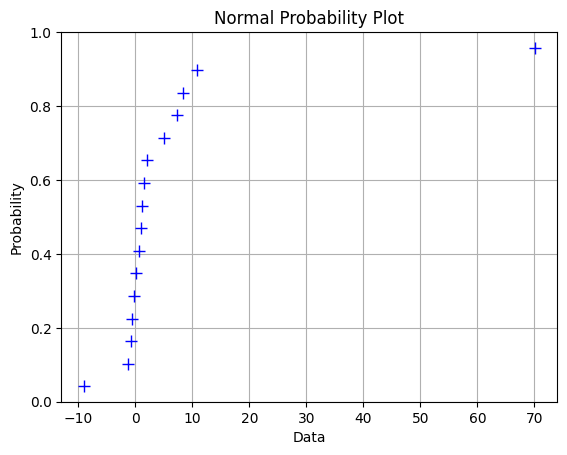

In [15]:
plt.figure()

# Blue crosses: data vs probability
plt.plot(osr, p, "b+", markersize=8)

# Optional: Red dashed reference line (same idea as MATLAB normplot)
#z_line = np.linspace(osm.min(), osm.max(), 200)
#p_line = stats.norm.cdf(z_line)
#x_line = slope * z_line + intercept
#plt.plot(x_line, p_line, "r--")

plt.xlabel("Data")
plt.ylabel("Probability")
plt.ylim(0, 1)
plt.grid(True)
plt.title("Normal Probability Plot")

In [17]:
cols = [0, 1, 3, 4, 6, 7, 10, 13]

Ar = A[:, cols]

In [18]:
betaDOE_r = np.linalg.inv(Ar.T @ Ar) @ (Ar.T @ y)
print("betaDOE_r =", betaDOE_r)

betaDOE_r = [70.0625 10.8125  4.9375  7.3125 -9.0625  8.3125 -0.5625 -0.8125]


In [20]:
Fr = Ar.T @ Ar
SSRi = np.diag(Fr) * betaDOE_r**2
print("SSRi =", SSRi)

SSRi = [7.85400625e+04 1.87056250e+03 3.90062500e+02 8.55562500e+02
 1.31406250e+03 1.10556250e+03 5.06250000e+00 1.05625000e+01]


In [21]:
SSE = y @ y - betaDOE_r @ (Ar.T @ y)
print("SSE  =", SSE)

SSE  = 179.5


In [22]:
l = 2      # number of levels
k = 3      # number of variables used in the F-test
nR = 2     # number of replicates (effective, via dropped parameter)

den_var = SSE / (l**k * (nR - 1))   # denominator variance
Fi = SSRi / den_var                 # F-statistic for each parameter

print("Fi   =", Fi)

Fi   = [3.50039276e+03 8.33676880e+01 1.73844011e+01 3.81309192e+01
 5.85654596e+01 4.92729805e+01 2.25626741e-01 4.70752089e-01]


In [23]:
alpha = 0.05
df1 = 1
df2 = l**k * (nR - 1)

Fcritp = stats.f.ppf(1 - alpha, df1, df2)
print("Fcritp =", Fcritp)

Fcritp = 5.317655071578714


In [24]:
significant_betas = betaDOE_r[Fi > Fcritp]
print("Significant betaDOE_r:", significant_betas)

Significant betaDOE_r: [70.0625 10.8125  4.9375  7.3125 -9.0625  8.3125]
